# TOPIC SENTENCE

## Background

## The Data

## Project Outlines

# 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Data Cleaning &  Data Processing

## 2.1. Data Inspection

In [2]:
# Reading the dataset

df = pd.read_csv('/Users/hazellie/desktop/MN5813/data.csv')
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJYGDEF5L,Thurston,Lacey,WA,98516.0,2020,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,291,0,22.0,124535071,POINT (-122.7474291 47.0821119),PUGET SOUND ENERGY INC,5.306701e+10
1,1N4BZ1CP1K,King,Sammamish,WA,98074.0,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,150,0,45.0,102359449,POINT (-122.0313266 47.6285782),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
2,5YJXCDE28G,King,Kent,WA,98031.0,2016,TESLA,MODEL X,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,200,0,33.0,228682037,POINT (-122.2012521 47.3931814),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
3,JHMZC5F37M,Kitsap,Poulsbo,WA,98370.0,2021,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,47,0,23.0,171566447,POINT (-122.64177 47.737525),PUGET SOUND ENERGY INC,5.303509e+10
4,WA1F2AFY4P,Thurston,Olympia,WA,98501.0,2023,AUDI,Q5 E,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,23,0,22.0,234923230,POINT (-122.89692 47.043535),PUGET SOUND ENERGY INC,5.306701e+10


In [3]:
# Counts of the Data Entries

df.shape

(163003, 17)

In [4]:
# Understanding the Dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 163003 entries, 0 to 163002
Data columns (total 17 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         163003 non-null  object 
 1   County                                             162999 non-null  object 
 2   City                                               162999 non-null  object 
 3   State                                              163003 non-null  object 
 4   Postal Code                                        162999 non-null  float64
 5   Model Year                                         163003 non-null  int64  
 6   Make                                               163003 non-null  object 
 7   Model                                              163003 non-null  object 
 8   Electric Vehicle Type                              163003 non-null  object

In [5]:
# Understanding the Dataset

df.describe()

,Postal Code,Model Year,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,2020 Census Tract
count,162999.000000,163003.000000,163003.000000,163003.000000,162637.000000,1.630030e+05,1.629990e+05
mean,98170.717422,2020.258449,63.382183,1198.344632,29.226861,2.153918e+08,5.297368e+10
std,2467.998984,3.005057,94.323062,8825.505678,14.841717,7.874180e+07,1.612977e+09
min,1730.000000,1997.000000,0.000000,0.000000,1.000000,4.385000e+03,1.081042e+09
25%,98052.000000,2018.000000,0.000000,0.000000,18.000000,1.762441e+08,5.303301e+10
50%,98122.000000,2021.000000,13.000000,0.000000,33.000000,2.209718e+08,5.303303e+10
75%,98370.000000,2023.000000,84.000000,0.000000,42.000000,2.495753e+08,5.305307e+10
max,99577.000000,2024.000000,337.000000,845000.000000,49.000000,4.792548e+08,5.603300e+10


## 2.2. Handling Missing Values

In [6]:
# Check the Number of Null Values in each Column

df.isnull().sum()

VIN (1-10)                                             0
County                                                 4
City                                                   4
State                                                  0
Postal Code                                            4
Model Year                                             0
Make                                                   0
Model                                                  0
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                         0
Base MSRP                                              0
Legislative District                                 366
DOL Vehicle ID                                         0
Vehicle Location                                       9
Electric Utility                                       4
2020 Census Tract                                      4
dtype: int64

In [7]:
# Fill in missing values in the categories with low number of null values

imputed_columns = ['County', 'City', 'Postal Code', 'Electric Utility']

for column in imputed_columns:
    df[column].fillna(df[column].mode()[0], inplace=True)

In [8]:
# Impute null values in "Legislative District" with Median
 
df['Legislative District'].fillna(df['Legislative District'].median(), inplace=True)

In [9]:
# Impute null values in "Model" with mapping dictionary

# Create a mapping dictionary based on 'Model Year' and 'Make'
mapping_dict = df.groupby(['Model Year', 'Make'])['Model'].apply(lambda x: x.mode().iloc[0] if not x.mode().empty else None).to_dict()

# Use the mapping dictionary to fill missing values in 'Model'
df['Model'] = df.apply(lambda row: mapping_dict.get((row['Model Year'], row['Make']), row['Model']), axis=1)

In [10]:
# Remove rows with missing values in "Vehicle Location" using .dropna()

df.dropna(subset=['Vehicle Location'], inplace=True)

In [11]:
# Doublecheck the Null Values 

df.isnull().sum()

VIN (1-10)                                           0
County                                               0
City                                                 0
State                                                0
Postal Code                                          0
Model Year                                           0
Make                                                 0
Model                                                0
Electric Vehicle Type                                0
Clean Alternative Fuel Vehicle (CAFV) Eligibility    0
Electric Range                                       0
Base MSRP                                            0
Legislative District                                 0
DOL Vehicle ID                                       0
Vehicle Location                                     0
Electric Utility                                     0
2020 Census Tract                                    0
dtype: int64

## 2.3. Data Cleaning

In [12]:
# Remove Columns that is not relevant to the analysis

df.drop(columns = ['2020 Census Tract', 'State'], axis=1, inplace=True)

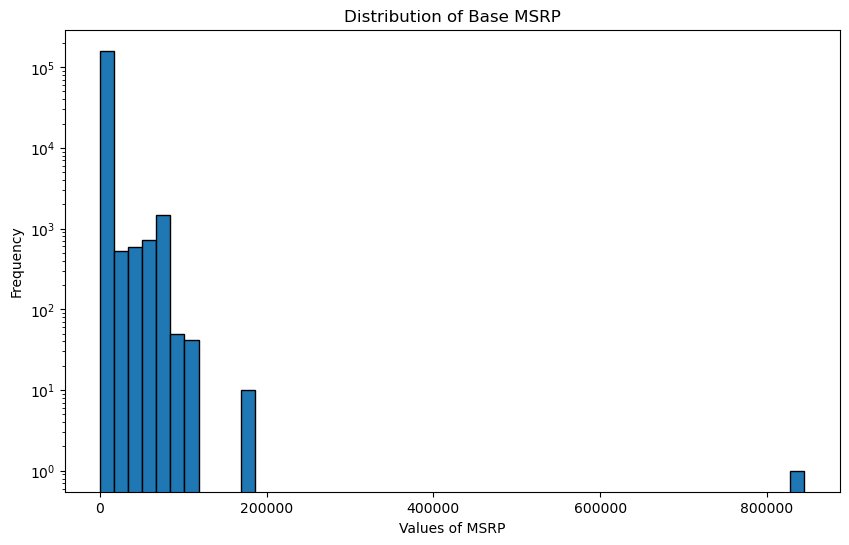

In [13]:
# Detect and Handling Data in Base MSRP

## Using histogram to see the distribution of the values in Base MSRP
plt.figure(figsize=(10, 6))
plt.hist(df['Base MSRP'], bins=50, edgecolor='black', log=True)
plt.title('Distribution of Base MSRP')
plt.xlabel('Values of MSRP')
plt.ylabel('Frequency')
plt.show()

In [14]:
# Remove Base MSRP row since most of the data are zero values

df.drop(columns = ['Base MSRP'], axis=1, inplace=True)

In [15]:
# Checking for Duplicate Values within the Data Frame

df.duplicated().sum()

0

## 2.4. Data Transformation

In [16]:
# Converting the Datatype of Postal Code from float64 to int
df['Postal Code'] = df['Postal Code'].astype(int)

In [17]:
# Rename Columns

df = df.rename(columns={'Clean Alternative Fuel Vehicle (CAFV) Eligibility':'CAFV Eligibility'})

In [18]:
df.head()

,VIN (1-10),County,City,Postal Code,Model Year,Make,Model,Electric Vehicle Type,CAFV Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility
0,5YJYGDEF5L,Thurston,Lacey,98516,2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,291,22.0,124535071,POINT (-122.7474291 47.0821119),PUGET SOUND ENERGY INC
1,1N4BZ1CP1K,King,Sammamish,98074,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,150,45.0,102359449,POINT (-122.0313266 47.6285782),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)
2,5YJXCDE28G,King,Kent,98031,2016,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,200,33.0,228682037,POINT (-122.2012521 47.3931814),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)
3,JHMZC5F37M,Kitsap,Poulsbo,98370,2021,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,47,23.0,171566447,POINT (-122.64177 47.737525),PUGET SOUND ENERGY INC
4,WA1F2AFY4P,Thurston,Olympia,98501,2023,AUDI,Q4,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,23,22.0,234923230,POINT (-122.89692 47.043535),PUGET SOUND ENERGY INC


## 2.5. Data Splitting

In [ ]:
# Extracting the longtitude and latitude from "Vehicle Location" variable

def extract_coordinates(point):
    point = point.replace('POINT (', '').replace(')', '')
    longitude, latitude = map(float, point.split())
    return pd.Series({'Longitude': longitude, 'Latitude': latitude})

# Create new columns for the extracted data

df[['Longitude', 'Latitude']] = df['Vehicle Location'].apply(extract_coordinates)

df

## 2.6. Data Exploration

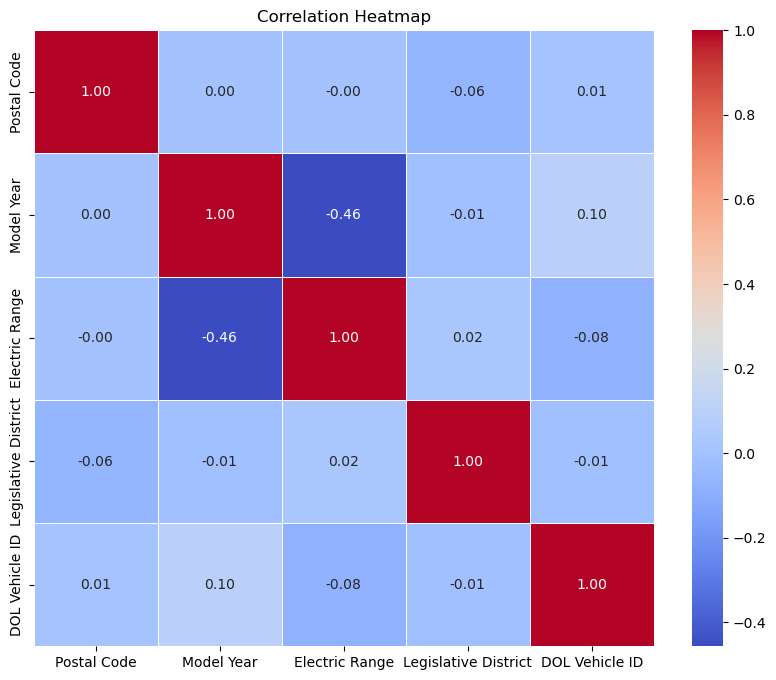

In [19]:
# The Correlation between Variables of the Dataset using HeatMap

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

# 3. Exploratory Data Analysis

## 3.1. Products Specification

### 3.1.1. Distribution of the Vehicle Types

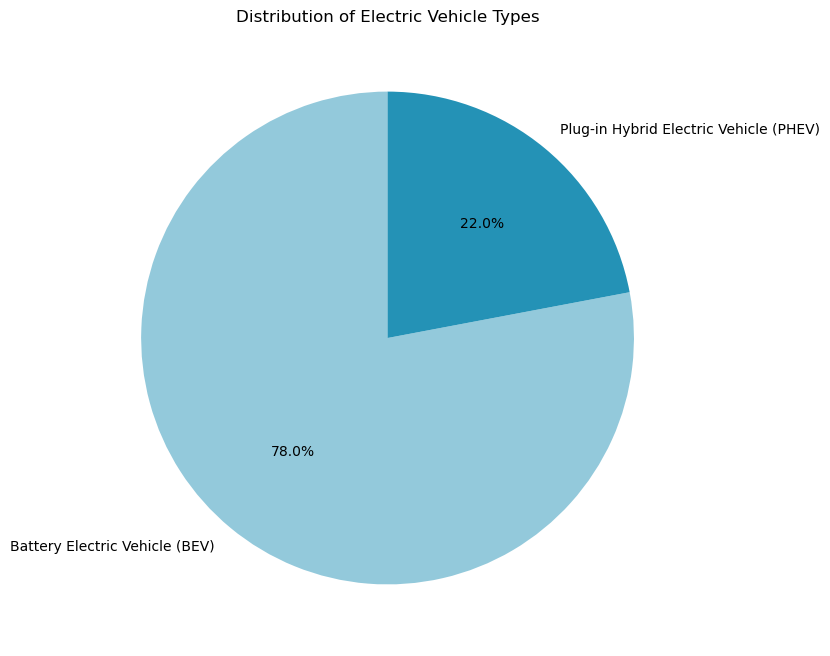

In [20]:
EV_Type = df['Electric Vehicle Type'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(EV_Type, labels=EV_Type.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('ocean_r'))
plt.title('Distribution of Electric Vehicle Types')
plt.show()

### 3.1.2. Electric Range by Electric Vehicle Type

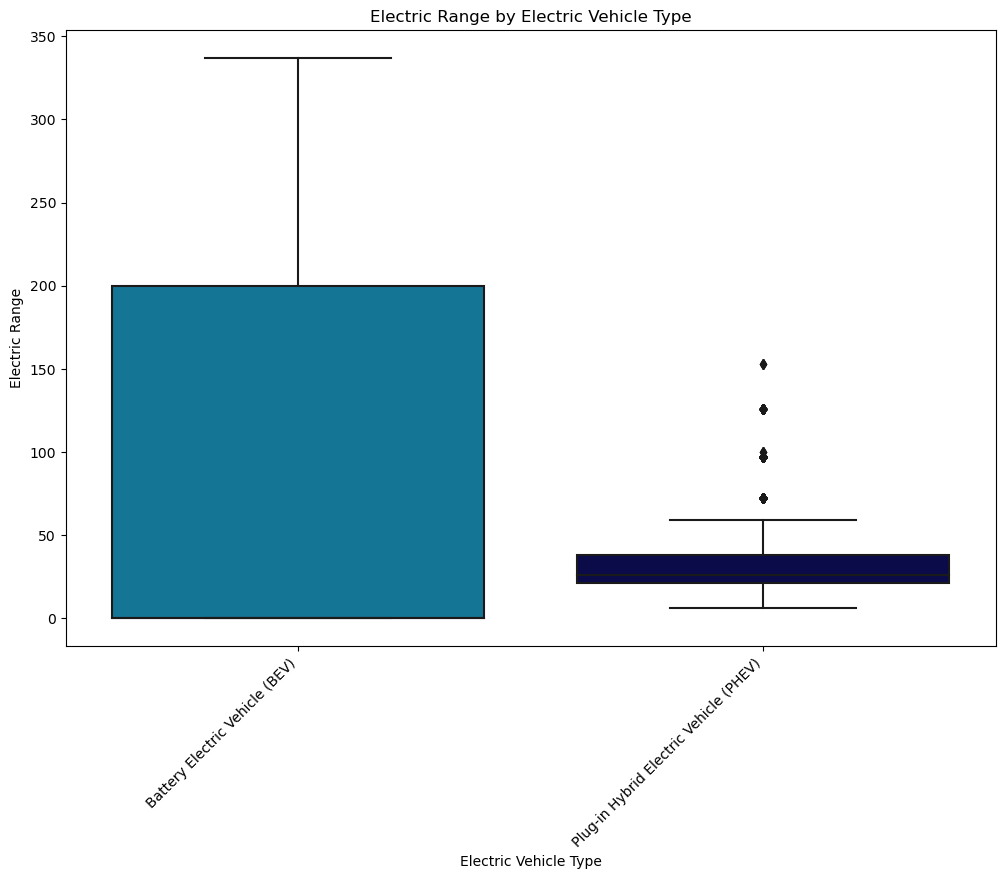

In [21]:
plt.figure(figsize=(12,8))
sns.boxplot(x='Electric Vehicle Type', y='Electric Range', data=df, palette='ocean_r')
plt.title('Electric Range by Electric Vehicle Type')
plt.xlabel('Electric Vehicle Type')
plt.ylabel('Electric Range')
plt.xticks(rotation=45, ha='right')
plt.show()

## 3.1. Distribution of EVs throughout the Years

In [22]:
# Group by "Model Year" and Total Amount of Registered Electric Vehicles (EVs) in each year

EV_Distribution = df.groupby('Model Year')['VIN (1-10)'].sum()

In [23]:
# Plotting the Bar Chart

plt.figure(figsize=(8,5))
plt.plot(EV_Distribution.index, EV_Distribution.values, marker='o', color='skyblue', linestyle='-', linewidth=2, markersize=5)
plt.title('Distribution of EVs throughout the years')
plt.xlabel('Year')
plt.ylabel('Number of EVs')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

ValueError: Image size of 4318595x468 pixels is too large. It must be less than 2^16 in each direction.

<Figure size 800x500 with 1 Axes>

## 3.2. Geographical Distribution

### i. The Distribution of EVs accross Different Counties and Cities

neen chuyen sang choropeth Map

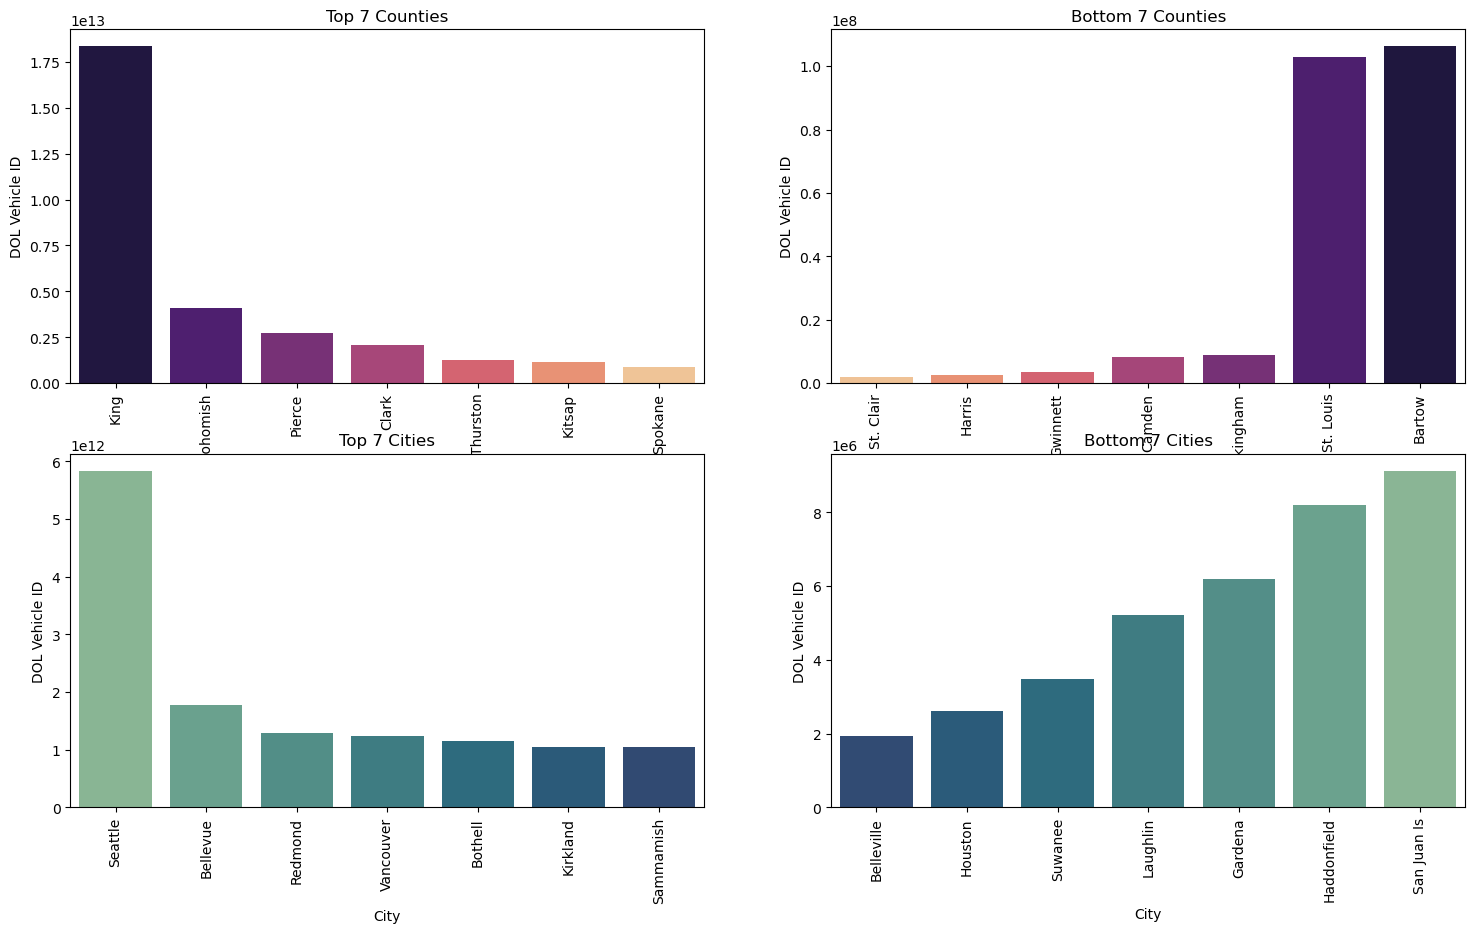

In [24]:
Top_Counties = df.groupby('County')['DOL Vehicle ID'].sum().nlargest(7).reset_index()

Bottom_Counties = df.groupby('County')['DOL Vehicle ID'].sum().nsmallest(7).reset_index()

Top_Cities = df.groupby('City')['DOL Vehicle ID'].sum().nlargest(7).reset_index()

Bottom_Cities = df.groupby('City')['DOL Vehicle ID'].sum().nsmallest(7).reset_index()

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18,2))

sns.barplot(x='County', y='DOL Vehicle ID', data=Top_Counties, palette='magma', ax=axes[0,0])
axes[0,0].set_title('Top 7 Counties')
axes[0,0].tick_params(axis='x', rotation=90)

sns.barplot(x='County', y='DOL Vehicle ID', data=Bottom_Counties, palette='magma_r', ax=axes[0,1])
axes[0,1].set_title('Bottom 7 Counties')
axes[0,1].tick_params(axis='x', rotation=90)

sns.barplot(x='City', y='DOL Vehicle ID', data=Top_Cities, palette='crest', ax=axes[1,0])
axes[1,0].set_title('Top 7 Cities')
axes[1,0].tick_params(axis='x', rotation=90)

sns.barplot(x='City', y='DOL Vehicle ID', data=Bottom_Cities, palette='crest_r', ax=axes[1,1])
axes[1,1].set_title('Bottom 7 Cities')
axes[1,1].tick_params(axis='x', rotation=90)

plt.subplots_adjust(top=4)

plt.show()

## 3.3. Top Selling EV Brands in Washington State

In [25]:
# Group by Manufacturers (Make) and the Total Amount of Registered Electric Vehicles (DOL Vehicle ID)

Top_Brands = df.groupby('Make')['DOL Vehicle ID'].sum().sort_values(ascending=False).head(10)

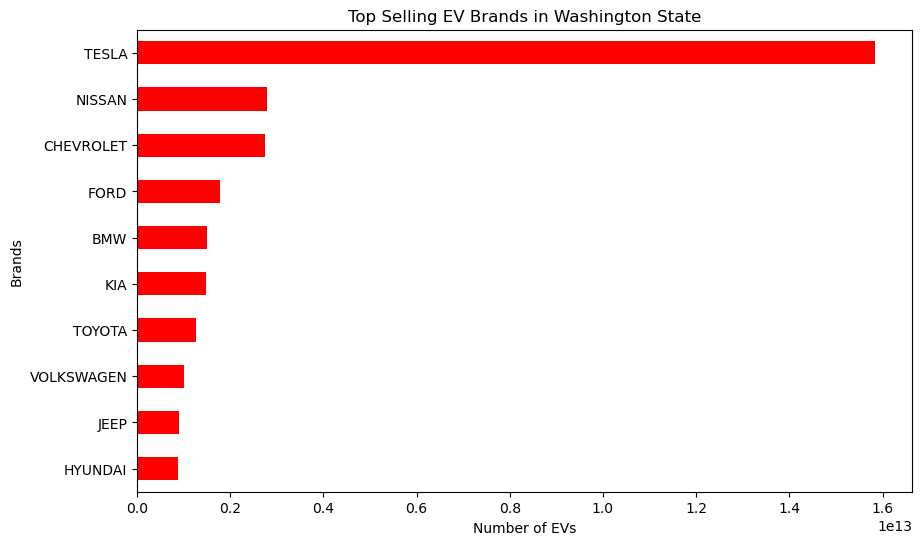

In [26]:
# Plotting the Bar Chart

plt.figure(figsize=(10,6))
Top_Brands.sort_values().plot(kind='barh', color='red')
plt.title('Top Selling EV Brands in Washington State')
plt.xlabel('Number of EVs')
plt.ylabel('Brands')
plt.show()

## 3.3.  Products Specification

### 3.3.1. Distribution of Electric Vehicle Types

<Figure size 1500x800 with 0 Axes>

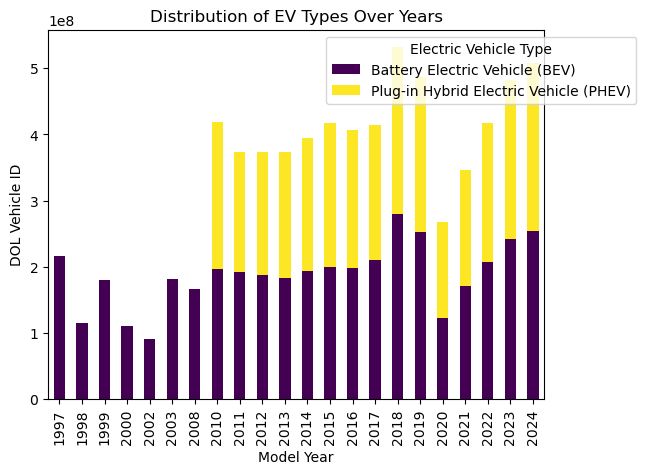

In [27]:
EV_Type_over_years = df.pivot_table(index='Model Year', columns='Electric Vehicle Type', values='DOL Vehicle ID', fill_value=0)

plt.figure(figsize=(15, 8))
EV_Type_over_years.plot(kind='bar', stacked=True, colormap='viridis')
plt.title('Distribution of EV Types Over Years')
plt.xlabel('Model Year')
plt.ylabel('DOL Vehicle ID')
plt.legend(title='Electric Vehicle Type', loc='upper right', bbox_to_anchor=(1.2, 1))
plt.show()